# Notebook 02: Phân khúc khách hàng bằng RFM và phân cụm

**Mục tiêu của notebook:**

1. Tính 3 chỉ số **RFM** cho mỗi khách hàng từ dữ liệu **giai đoạn quan sát** (trước ngày 10/09/2011):
   - **Recency (R):** số ngày từ lần mua cuối đến ngày tham chiếu 10/09/2011. Càng nhỏ càng tốt.
   - **Frequency (F):** số hóa đơn khác nhau. Càng lớn càng tốt.
   - **Monetary (M):** tổng tiền đã chi (GBP). Càng lớn càng tốt.
2. Tiền xử lý (biến đổi `log1p`, chuẩn hóa), chọn số cụm `k` bằng Elbow và Silhouette.
3. Phân cụm bằng **K-Means**, so sánh với **GMM** và **Agglomerative**.
4. Mô tả, đặt tên và trực quan hóa từng cụm; xem tỷ lệ churn của mỗi cụm.

**Đầu vào:** `transactions_clean.csv`, `customers.csv` (từ notebook 01).
**Đầu ra:** `data/processed/customers_clustered.csv` gồm `CustomerID`, `Recency`, `Frequency`, `Monetary`, `Cluster`, `ClusterName`, `churn`.

## 0. Khai báo thư viện và hằng số

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.mixture import GaussianMixture
from sklearn.decomposition import PCA
from sklearn.metrics import silhouette_score, davies_bouldin_score

pd.set_option("display.float_format", "{:,.2f}".format)

RANDOM_STATE = 42
PROCESSED_DIR = Path("../data/processed")
FIG_DIR = Path("../figures")
REF_DATE = pd.Timestamp("2011-09-10")  # reference date = end of the observation period
RFM_COLS = ["Recency", "Frequency", "Monetary"]

In [2]:
# Shared chart style for every notebook (light surface, thin marks, recessive grid)
COLORS = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#6250d6", "#e34948"]
INK, INK_2, MUTED, GRID = "#0b0b0b", "#52514e", "#898781", "#e1e0d9"

plt.rcParams.update({
    "figure.dpi": 100, "savefig.dpi": 150, "savefig.bbox": "tight",
    "figure.facecolor": "white", "axes.facecolor": "white", "savefig.facecolor": "white",
    "axes.edgecolor": "#c3c2b7", "axes.linewidth": 0.8,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "axes.grid.axis": "y", "grid.color": GRID, "grid.linewidth": 0.8,
    "axes.axisbelow": True,
    "axes.titlesize": 12, "axes.titleweight": "bold", "axes.titlecolor": INK, "axes.titlelocation": "left",
    "axes.labelcolor": INK_2, "axes.labelsize": 10,
    "xtick.color": INK_2, "ytick.color": INK_2, "xtick.labelsize": 9, "ytick.labelsize": 9,
    "text.color": INK, "legend.frameon": False, "legend.fontsize": 9,
    "lines.linewidth": 2, "lines.solid_capstyle": "round", "lines.solid_joinstyle": "round",
    "axes.prop_cycle": plt.cycler(color=COLORS),
    "axes.unicode_minus": False,  # negative numbers use the ASCII "-" instead of the Unicode minus sign
})


def save_fig(fig, filename):
    """Save a figure as PNG into the figures/ folder."""
    fig.savefig(FIG_DIR / filename)
    print(f"Đã lưu: figures/{filename}")

## 1. Đọc dữ liệu và lọc giai đoạn quan sát

Chỉ dùng giao dịch **trước ngày 10/09/2011** của các khách trong tập nghiên cứu (`customers.csv`). Dữ liệu của giai đoạn dự đoán không được dùng ở đây để tránh rò rỉ dữ liệu.

In [3]:
transactions = pd.read_csv(
    PROCESSED_DIR / "transactions_clean.csv",
    dtype={"Invoice": str, "StockCode": str},
    parse_dates=["InvoiceDate"],
)
customers = pd.read_csv(PROCESSED_DIR / "customers.csv")

obs = transactions[
    (transactions["InvoiceDate"] < REF_DATE)
    & transactions["CustomerID"].isin(customers["CustomerID"])
]
print(f"Giao dịch đã làm sạch: {len(transactions):,} dòng")
print(f"Giao dịch giai đoạn quan sát của tập nghiên cứu: {len(obs):,} dòng, "
      f"{obs['CustomerID'].nunique():,} khách, đến ngày {obs['InvoiceDate'].max():%d/%m/%Y}")

Giao dịch đã làm sạch: 770,688 dòng
Giao dịch giai đoạn quan sát của tập nghiên cứu: 582,831 dòng, 4,299 khách, đến ngày 09/09/2011


## 2. Tính RFM

- `Recency` tính theo **ngày** (bỏ phần giờ), nên khách mua lần cuối ngày 09/09/2011 có Recency = 1.
- Cột `FirstPurchase` chỉ dùng để mô tả thêm "thâm niên" của từng cụm ở mục 6, **không** đưa vào phân cụm.
- Nhãn `churn` được gắn kèm chỉ để **mô tả** các cụm sau khi phân cụm; thuật toán phân cụm không nhìn thấy nhãn này.

In [4]:
rfm = obs.groupby("CustomerID").agg(
    FirstPurchase=("InvoiceDate", "min"),
    LastPurchase=("InvoiceDate", "max"),
    Frequency=("Invoice", "nunique"),
    Monetary=("TotalPrice", "sum"),
)
rfm["Recency"] = (REF_DATE - rfm["LastPurchase"].dt.normalize()).dt.days
rfm["Tenure"] = (REF_DATE - rfm["FirstPurchase"].dt.normalize()).dt.days
rfm = rfm.join(customers.set_index("CustomerID")["churn"])

print(f"Số khách: {len(rfm):,}")
rfm[RFM_COLS].describe(percentiles=[0.25, 0.5, 0.75, 0.95, 0.99]).T

Số khách: 4,299


,count,mean,std,min,25%,50%,75%,95%,99%,max
Recency,"4,299.00",143.66,116.50,1.00,37.00,111.00,271.00,338.00,358.00,365.00
Frequency,"4,299.00",6.53,12.06,1.00,2.00,3.00,7.00,21.00,46.00,280.00
Monetary,"4,299.00","2,961.48","13,026.48",2.90,404.43,962.90,"2,439.78","9,204.13","27,912.98","454,922.09"


## 3. Phân phối RFM và biến đổi `log1p`

K-Means dựa trên khoảng cách Euclid nên rất nhạy với các biến lệch và có đơn vị khác nhau. Ta xem phân phối gốc, sau đó biến đổi `log1p(x) = log(1 + x)` để giảm độ lệch.

,Độ lệch (skewness) gốc,Độ lệch sau log1p
Recency,0.44,-0.92
Frequency,9.69,0.90
Monetary,22.59,0.26


Đã lưu: figures/02_phan_phoi_rfm.png


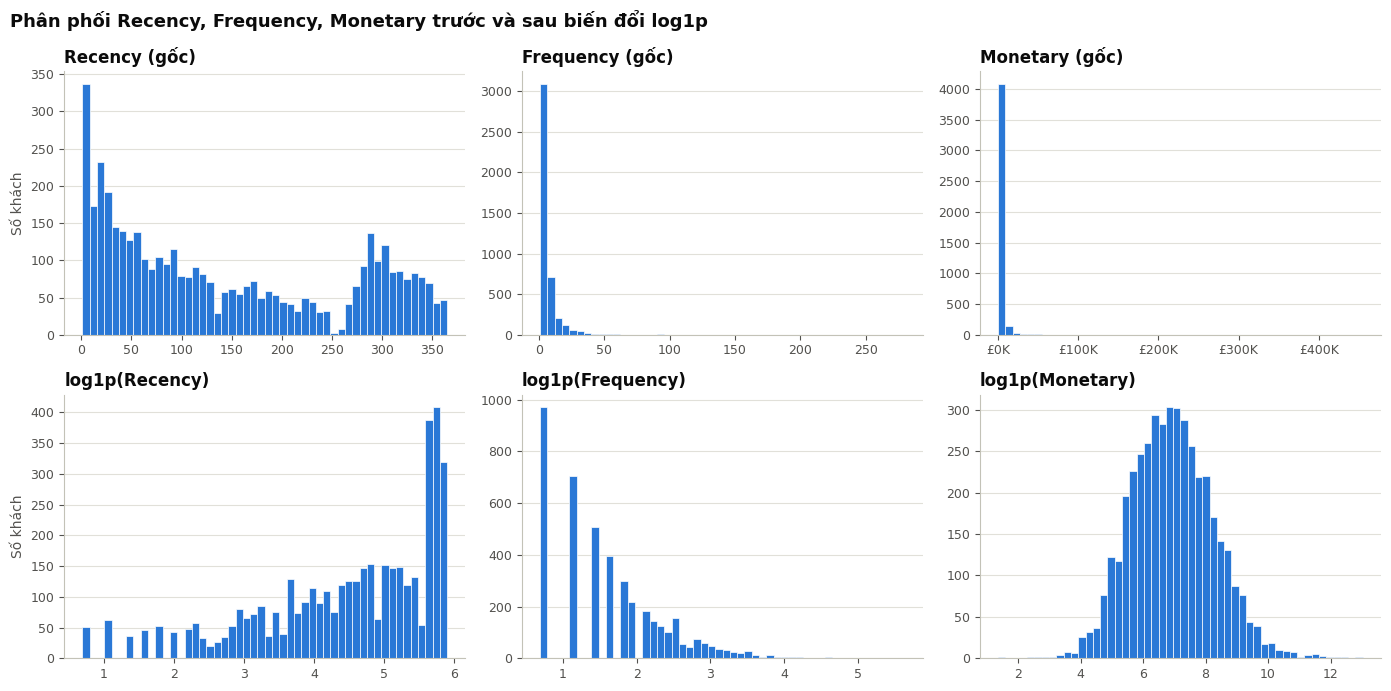

In [5]:
rfm_log = np.log1p(rfm[RFM_COLS])

skewness = pd.DataFrame({
    "Độ lệch (skewness) gốc": rfm[RFM_COLS].skew(),
    "Độ lệch sau log1p": rfm_log.skew(),
})
display(skewness)

fig, axes = plt.subplots(2, 3, figsize=(14, 7))
for j, col in enumerate(RFM_COLS):
    axes[0, j].hist(rfm[col], bins=50, color=COLORS[0], edgecolor="white", linewidth=0.5)
    axes[0, j].set_title(f"{col} (gốc)")
    axes[1, j].hist(rfm_log[col], bins=50, color=COLORS[0], edgecolor="white", linewidth=0.5)
    axes[1, j].set_title(f"log1p({col})")
    axes[0, j].set_ylabel("Số khách" if j == 0 else "")
    axes[1, j].set_ylabel("Số khách" if j == 0 else "")
axes[0, 2].xaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f"£{x / 1e3:,.0f}K"))
fig.suptitle("Phân phối Recency, Frequency, Monetary trước và sau biến đổi log1p",
             x=0.01, ha="left", fontsize=13, fontweight="bold")
fig.tight_layout()
save_fig(fig, "02_phan_phoi_rfm.png")
plt.show()

**Nhận xét:** - **Frequency** (độ lệch 9,7) và **Monetary** (độ lệch 22,6) lệch phải cực mạnh: phần lớn khách mua ít, chi ít, trong khi vài khách mua hàng trăm lần hoặc chi hàng trăm nghìn bảng. Sau `log1p`, độ lệch giảm còn 0,90 và 0,26, phân phối gần đối xứng hơn nhiều.
- **Recency** nằm trong khoảng 1 đến 365 ngày (do tập nghiên cứu chỉ gồm khách có mua trong 12 tháng cuối) và chỉ lệch nhẹ. Sau `log1p`, Recency lệch sang trái: phép log "giãn" vùng giá trị nhỏ, nghĩa là chênh lệch giữa 5 ngày và 30 ngày được coi trọng hơn chênh lệch giữa 300 và 330 ngày. Điều này hợp lý về mặt kinh doanh. Mục 5 có phần kiểm tra thêm cho lựa chọn này.
- Histogram Recency gốc có một **khoảng trống quanh 250 đến 260 ngày**, ứng với khoảng 24/12/2010 đến 04/01/2011, khi cửa hàng nghỉ lễ Giáng sinh. Ngay trước đó (khoảng 280 đến 300 ngày, tức cuối tháng 11/2010) có một "gò" cao: nhiều khách mua lần cuối vào mùa cao điểm 2010 rồi không quay lại.

## 4. Chuẩn hóa dữ liệu

Sau `log1p`, ba biến vẫn có thang đo khác nhau, nên dùng `StandardScaler` đưa về trung bình 0, độ lệch chuẩn 1, để mỗi biến đóng góp ngang nhau vào khoảng cách.

*Ghi chú:* phân cụm là học không giám sát và không dùng nhãn churn, nên việc fit scaler trên toàn bộ khách hàng ở đây không gây rò rỉ nhãn.

In [6]:
scaler = StandardScaler()
X = scaler.fit_transform(rfm_log)
pd.DataFrame(X, columns=RFM_COLS).describe().loc[["mean", "std", "min", "max"]]

,Recency,Frequency,Monetary
mean,-0.00,-0.00,-0.00
std,1.00,1.00,1.00
min,-2.90,-1.16,-4.22
max,1.15,5.07,4.62


## 5. Chọn số cụm k

Thử `k = 2, ..., 10` với K-Means và tính 3 chỉ số:

- **Inertia** (tổng bình phương khoảng cách tới tâm cụm, dùng cho phương pháp **Elbow**): càng nhỏ càng chặt, nhưng luôn giảm khi tăng k, nên ta tìm "khuỷu tay" nơi mức giảm chậm lại.
- **Silhouette** (từ -1 đến 1): càng cao thì các cụm càng tách biệt.
- **Davies-Bouldin**: càng thấp càng tốt.

In [7]:
k_values = range(2, 11)
rows = []
for k in k_values:
    km = KMeans(n_clusters=k, n_init=10, random_state=RANDOM_STATE).fit(X)
    rows.append({
        "k": k,
        "Inertia": km.inertia_,
        "Silhouette": silhouette_score(X, km.labels_),
        "Davies-Bouldin": davies_bouldin_score(X, km.labels_),
    })
k_scores = pd.DataFrame(rows).set_index("k")
k_scores.style.format({"Inertia": "{:,.0f}", "Silhouette": "{:.3f}", "Davies-Bouldin": "{:.3f}"}) \
    .highlight_max(subset=["Silhouette"], color="#cde2fb") \
    .highlight_min(subset=["Davies-Bouldin"], color="#cde2fb")

,Inertia,Silhouette,Davies-Bouldin
k,,,
2,"6,560",0.436,0.901
3,"4,940",0.333,1.043
4,"3,844",0.361,0.907
5,"3,214",0.321,0.963
6,"2,807",0.317,0.961
7,"2,530",0.287,1.008
8,"2,287",0.294,0.995
9,"2,102",0.301,0.973
10,"1,940",0.279,0.985


Đã lưu: figures/02_chon_so_cum_k.png


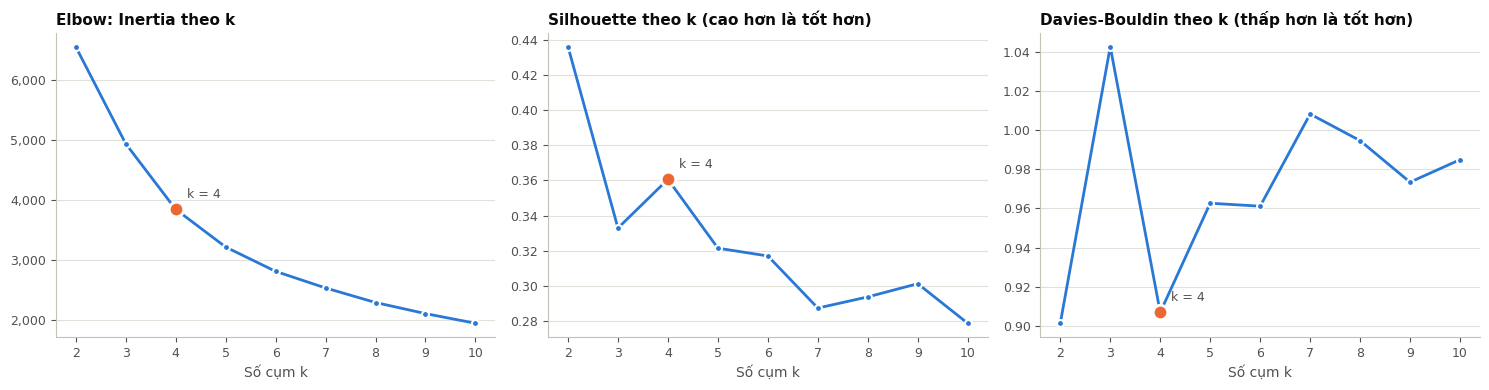

In [8]:
K = 4  # chosen number of clusters (see the discussion below)

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, col, title in [
    (axes[0], "Inertia", "Elbow: Inertia theo k"),
    (axes[1], "Silhouette", "Silhouette theo k (cao hơn là tốt hơn)"),
    (axes[2], "Davies-Bouldin", "Davies-Bouldin theo k (thấp hơn là tốt hơn)"),
]:
    ax.plot(k_scores.index, k_scores[col], color=COLORS[0], marker="o", markersize=5,
            markeredgecolor="white", markeredgewidth=1.5)
    ax.scatter([K], [k_scores.loc[K, col]], s=110, color=COLORS[1], edgecolor="white", linewidth=2, zorder=3)
    ax.annotate(f"k = {K}", (K, k_scores.loc[K, col]), xytext=(8, 8), textcoords="offset points",
                fontsize=9, color=INK_2)
    ax.set_title(title, fontsize=11)
    ax.set_xlabel("Số cụm k")
    ax.set_xticks(list(k_values))
axes[0].yaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f"{x:,.0f}"))
fig.tight_layout()
save_fig(fig, "02_chon_so_cum_k.png")
plt.show()

**Nhận xét và lựa chọn k:** - **Elbow:** inertia giảm nhanh từ k = 2 đến k = 4, sau đó giảm chậm dần. "Khuỷu tay" không thật sắc nét (thường gặp với dữ liệu thực) nhưng nằm quanh k = 4.
- **Silhouette** cao nhất ở k = 2 (0,436). Tuy nhiên k = 2 chỉ chia khách thành hai nhóm "tốt" và "kém", quá thô để xây dựng chiến lược riêng. Trong các giá trị k ≥ 3, **k = 4 có Silhouette cao nhất (0,361)**, tạo thành một đỉnh cục bộ rõ ràng.
- **Davies-Bouldin** ở k = 4 là 0,907, gần bằng mức thấp nhất (0,901 ở k = 2) và thấp hơn mọi k ≥ 3.

-> **Chọn k = 4**, cân bằng giữa chất lượng cụm và khả năng diễn giải. Silhouette khoảng 0,36 cho thấy cấu trúc cụm ở mức trung bình: khách hàng phân bố liên tục chứ không tách thành các nhóm rời hẳn nhau, điều này bình thường với dữ liệu RFM.

**Kiểm tra thêm về biến đổi Recency.** Recency gốc chỉ lệch nhẹ, nên một câu hỏi tự nhiên là có cần `log1p` cho Recency hay không. Ta thử phương án chỉ log hóa F và M, giữ Recency ở thang gốc, rồi so sánh ở cùng k = 4.

In [9]:
rfm_alt = rfm[RFM_COLS].assign(Frequency=np.log1p(rfm["Frequency"]), Monetary=np.log1p(rfm["Monetary"]))
X_alt = StandardScaler().fit_transform(rfm_alt)
labels_alt = KMeans(n_clusters=K, n_init=10, random_state=RANDOM_STATE).fit_predict(X_alt)

labels_main = KMeans(n_clusters=K, n_init=10, random_state=RANDOM_STATE).fit_predict(X)
churn_main = rfm.groupby(labels_main)["churn"].mean().sort_values().mul(100).round(1).tolist()
churn_alt = rfm.groupby(labels_alt)["churn"].mean().sort_values().mul(100).round(1).tolist()
print(f"log1p cả 3 biến : Silhouette = {silhouette_score(X, labels_main):.3f}, tỷ lệ churn các cụm (%) = {churn_main}")
print(f"Giữ Recency gốc : Silhouette = {silhouette_score(X_alt, labels_alt):.3f}, tỷ lệ churn các cụm (%) = {churn_alt}")

log1p cả 3 biến : Silhouette = 0.361, tỷ lệ churn các cụm (%) = [14.1, 42.3, 47.5, 71.4]


Giữ Recency gốc : Silhouette = 0.356, tỷ lệ churn các cụm (%) = [12.5, 39.7, 59.6, 71.2]


**Nhận xét:** Phương án giữ Recency gốc cho Silhouette thấp hơn một chút (0,356 so với 0,361), nhưng lại phân tách tỷ lệ churn của hai nhóm giữa rộng hơn (khoảng 40% và 60%, so với 42% và 48% của phương án chính). Đổi lại, phương án này không tạo ra được nhóm "Khách mới" rõ ràng: các khách mới mua gần đây bị trộn vào những nhóm khác.

Mục tiêu của bước phân cụm là **phân khúc khách hàng theo hành vi** để xây dựng chiến lược; việc dự đoán churn cho từng khách do mô hình ở notebook 03 đảm nhận. Vì vậy ta ưu tiên chất lượng cụm và khả năng diễn giải, giữ cách làm chuẩn: `log1p` cho cả 3 biến. (Lưu ý: so sánh Silhouette giữa hai không gian đặc trưng khác nhau chỉ mang tính tham khảo.)

## 6. Phân cụm với k = 4 và so sánh 3 thuật toán

- **K-Means:** gán mỗi khách vào tâm cụm gần nhất, các cụm có dạng "hình cầu".
- **GMM (Gaussian Mixture Model):** mỗi cụm là một phân phối chuẩn nhiều chiều, cho phép cụm có hình elip.
- **Agglomerative (Ward):** phân cụm phân cấp từ dưới lên, mỗi bước gộp hai cụm làm tổng phương sai tăng ít nhất.

Cả ba được so sánh trên cùng dữ liệu `X` bằng Silhouette và Davies-Bouldin.

In [10]:
kmeans = KMeans(n_clusters=K, n_init=10, random_state=RANDOM_STATE).fit(X)
labels_kmeans = kmeans.labels_

gmm = GaussianMixture(n_components=K, random_state=RANDOM_STATE).fit(X)
labels_gmm = gmm.predict(X)

labels_agg = AgglomerativeClustering(n_clusters=K, linkage="ward").fit_predict(X)

algo_compare = pd.DataFrame([
    {
        "Thuật toán": name,
        "Silhouette": silhouette_score(X, labels),
        "Davies-Bouldin": davies_bouldin_score(X, labels),
        "Kích thước các cụm": sorted(np.bincount(labels).tolist(), reverse=True),
    }
    for name, labels in [("K-Means", labels_kmeans), ("GMM", labels_gmm), ("Agglomerative (Ward)", labels_agg)]
])
algo_compare.style.format({"Silhouette": "{:.3f}", "Davies-Bouldin": "{:.3f}"}).hide(axis="index")

Thuật toán,Silhouette,Davies-Bouldin,Kích thước các cụm
K-Means,0.361,0.907,"[1536, 1410, 790, 563]"
GMM,0.171,1.340,"[1525, 1175, 970, 629]"
Agglomerative (Ward),0.275,1.189,"[1917, 973, 830, 579]"


**Nhận xét:** **K-Means tốt nhất trên cả hai chỉ số**: Silhouette 0,361 (Agglomerative 0,275, GMM 0,171) và Davies-Bouldin 0,907 (Agglomerative 1,189, GMM 1,340). GMM cho phép các cụm hình elip chồng lấn nhau nên ranh giới cụm kém rõ hơn theo khoảng cách. Cần lưu ý cả hai chỉ số này đều dựa trên khoảng cách nên có phần "ưu ái" các cụm dạng cầu như của K-Means. Kết hợp với ưu điểm đơn giản, nhanh và dễ giải thích, ta **chọn K-Means** làm kết quả phân cụm chính.

## 7. Mô tả và đặt tên cụm

Số thứ tự cụm do K-Means sinh ra là ngẫu nhiên, nên trước hết xem giá trị RFM trung bình theo nhãn gốc của K-Means.

In [11]:
rfm["KMeansLabel"] = labels_kmeans
rfm.groupby("KMeansLabel")[RFM_COLS + ["Tenure", "churn"]].mean().assign(
    NumCustomers=rfm["KMeansLabel"].value_counts().sort_index())

,Recency,Frequency,Monetary,Tenure,churn,NumCustomers
KMeansLabel,,,,,,
0,27.61,20.25,"11,088.51",557.32,0.14,790
1,231.56,1.62,396.13,312.69,0.71,1536
2,24.20,2.92,815.35,227.87,0.42,563
3,160.63,5.65,"2,059.57",505.41,0.48,1410


Dựa vào bảng trên, ta đặt tên cụm theo các quy tắc sau (viết thành code để kết quả không phụ thuộc vào thứ tự nhãn ngẫu nhiên của K-Means):

1. Cụm có **Frequency trung bình cao nhất** -> **VIP** (mua thường xuyên, chi tiêu nhiều, mới mua gần đây).
2. Trong các cụm còn lại, cụm có **Recency thấp nhất** (mới mua gần đây) -> **Khách mới** (mua gần đây nhưng ít lần, thâm niên ngắn).
3. Trong hai cụm còn lại, cụm có **Frequency cao hơn** -> **Có nguy cơ** (từng mua khá đều nhưng đã lâu không quay lại).
4. Cụm cuối cùng -> **Ngủ đông** (mua rất ít, đã lâu không quay lại).

Sau đó đánh số lại `Cluster` theo thứ tự 0 = VIP, 1 = Khách mới, 2 = Có nguy cơ, 3 = Ngủ đông.

In [12]:
profile_raw = rfm.groupby("KMeansLabel")[RFM_COLS].mean()

vip = profile_raw["Frequency"].idxmax()
remaining = profile_raw.drop(index=vip)
new = remaining["Recency"].idxmin()
remaining = remaining.drop(index=new)
at_risk = remaining["Frequency"].idxmax()
dormant = remaining["Frequency"].idxmin()

label_to_cluster = {int(vip): 0, int(new): 1, int(at_risk): 2, int(dormant): 3}  # plain ints for printing
CLUSTER_NAMES = {0: "VIP", 1: "Khách mới", 2: "Có nguy cơ", 3: "Ngủ đông"}
CLUSTER_ORDER = list(CLUSTER_NAMES.values())
CLUSTER_COLORS = dict(zip(CLUSTER_ORDER, COLORS[:4]))

rfm["Cluster"] = rfm["KMeansLabel"].map(label_to_cluster)
rfm["ClusterName"] = rfm["Cluster"].map(CLUSTER_NAMES)
print("Nhãn K-Means -> Cluster mới:", label_to_cluster)

Nhãn K-Means -> Cluster mới: {0: 0, 2: 1, 3: 2, 1: 3}


In [13]:
total_revenue = rfm["Monetary"].sum()
cluster_profile = rfm.groupby("ClusterName").agg(
    NumCustomers=("Recency", "size"),
    Recency_mean=("Recency", "mean"),
    Recency_median=("Recency", "median"),
    Frequency_mean=("Frequency", "mean"),
    Frequency_median=("Frequency", "median"),
    Monetary_mean=("Monetary", "mean"),
    Monetary_median=("Monetary", "median"),
    Monetary_sum=("Monetary", "sum"),
    Tenure_mean=("Tenure", "mean"),
    ChurnRate=("churn", "mean"),
).reindex(CLUSTER_ORDER)
cluster_profile["CustomerShare"] = cluster_profile["NumCustomers"] / len(rfm) * 100
cluster_profile["RevenueShare"] = cluster_profile["Monetary_sum"] / total_revenue * 100
cluster_profile["ChurnRate"] = cluster_profile["ChurnRate"] * 100

profile_table = cluster_profile[[
    "NumCustomers", "CustomerShare", "Recency_mean", "Frequency_mean", "Monetary_mean",
    "Monetary_median", "Tenure_mean", "RevenueShare", "ChurnRate",
]].rename(columns={
    "NumCustomers": "Số khách", "CustomerShare": "% khách", "Recency_mean": "Recency TB (ngày)",
    "Frequency_mean": "Frequency TB", "Monetary_mean": "Monetary TB (£)", "Monetary_median": "Monetary trung vị (£)",
    "Tenure_mean": "Thâm niên TB (ngày)", "RevenueShare": "% doanh thu", "ChurnRate": "Tỷ lệ churn (%)",
})
profile_table.style.format({
    "Số khách": "{:,.0f}", "% khách": "{:.1f}", "Recency TB (ngày)": "{:.1f}", "Frequency TB": "{:.1f}",
    "Monetary TB (£)": "{:,.0f}", "Monetary trung vị (£)": "{:,.0f}", "Thâm niên TB (ngày)": "{:,.0f}",
    "% doanh thu": "{:.1f}", "Tỷ lệ churn (%)": "{:.1f}",
})

,Số khách,% khách,Recency TB (ngày),Frequency TB,Monetary TB (£),Monetary trung vị (£),Thâm niên TB (ngày),% doanh thu,Tỷ lệ churn (%)
ClusterName,,,,,,,,,
VIP,790,18.4,27.6,20.3,"11,089","5,445",557,68.8,14.1
Khách mới,563,13.1,24.2,2.9,815,646,228,3.6,42.3
Có nguy cơ,"1,410",32.8,160.6,5.6,"2,060","1,565",505,22.8,47.5
Ngủ đông,"1,536",35.7,231.6,1.6,396,334,313,4.8,71.4


**Mô tả các cụm:**

| Cụm | Đặc điểm chính | Ý nghĩa |
|---|---|---|
| **VIP** (790 khách, 18%) | Mua gần đây (Recency TB 28 ngày), rất thường xuyên (TB 20 hóa đơn), chi tiêu cao (TB £11.089, trung vị £5.445), thâm niên lâu nhất (TB 557 ngày) | Chỉ 18% số khách nhưng đóng góp **69% doanh thu**. Tỷ lệ churn thấp nhất (14%) |
| **Khách mới** (563 khách, 13%) | Mua gần đây (Recency TB 24 ngày) nhưng ít lần (TB 2,9 hóa đơn), chi tiêu thấp (TB £815), thâm niên ngắn (TB 228 ngày, khoảng 7,5 tháng) | Khách mới bắt đầu quan hệ với cửa hàng. Churn 42%: gần một nửa không quay lại, đây là giai đoạn quyết định để giữ chân |
| **Có nguy cơ** (1.410 khách, 33%) | Từng mua khá đều (TB 5,6 hóa đơn, £2.060, thâm niên 505 ngày) nhưng đã lâu không quay lại (Recency TB 161 ngày, khoảng 5 tháng) | Đóng góp 23% doanh thu. Churn 48%. Nhóm **đáng cứu nhất** vì có giá trị lịch sử khá và số lượng lớn |
| **Ngủ đông** (1.536 khách, 36%) | Mua 1 đến 2 lần (TB 1,6 hóa đơn), chi ít (TB £396), lần mua cuối đã 7 đến 8 tháng (Recency TB 232 ngày) | Chỉ 5% doanh thu, churn cao nhất (71%) |

## 8. Trực quan hóa các cụm

### 8.1. Snake plot

Snake plot vẽ giá trị trung bình **đã chuẩn hóa** (sau `log1p` và `StandardScaler`) của R, F, M cho từng cụm. Giá trị 0 là mức trung bình của toàn bộ khách hàng. Lưu ý: với Recency, giá trị **thấp** mới là tốt.

Đã lưu: figures/02_snake_plot.png


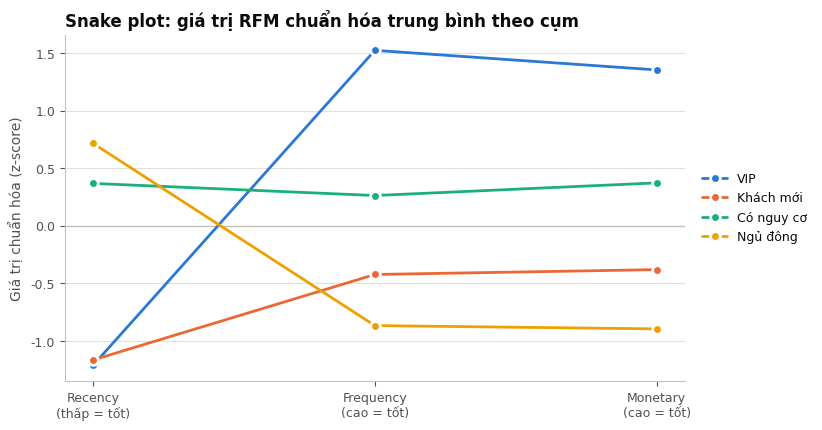

,Recency,Frequency,Monetary
ClusterName,,,
VIP,-1.21,1.52,1.35
Khách mới,-1.17,-0.42,-0.38
Có nguy cơ,0.37,0.26,0.37
Ngủ đông,0.71,-0.87,-0.90


In [14]:
X_df = pd.DataFrame(X, columns=RFM_COLS, index=rfm.index)
X_df["ClusterName"] = rfm["ClusterName"]
snake = X_df.groupby("ClusterName")[RFM_COLS].mean().reindex(CLUSTER_ORDER)

fig, ax = plt.subplots(figsize=(8, 4.5))
ax.axhline(0, color="#c3c2b7", linewidth=1)
for name in CLUSTER_ORDER:
    ax.plot(RFM_COLS, snake.loc[name], color=CLUSTER_COLORS[name], marker="o", markersize=7,
            markeredgecolor="white", markeredgewidth=2, label=name)
ax.set_title("Snake plot: giá trị RFM chuẩn hóa trung bình theo cụm")
ax.set_ylabel("Giá trị chuẩn hóa (z-score)")
ax.set_xticks(range(3), ["Recency\n(thấp = tốt)", "Frequency\n(cao = tốt)", "Monetary\n(cao = tốt)"])
ax.legend(loc="center left", bbox_to_anchor=(1.01, 0.5))
save_fig(fig, "02_snake_plot.png")
plt.show()
snake

### 8.2. Boxplot R, F, M theo cụm

Frequency và Monetary được vẽ trên **thang log** để thấy rõ cả các cụm có giá trị nhỏ.

Đã lưu: figures/02_boxplot_rfm_theo_cum.png


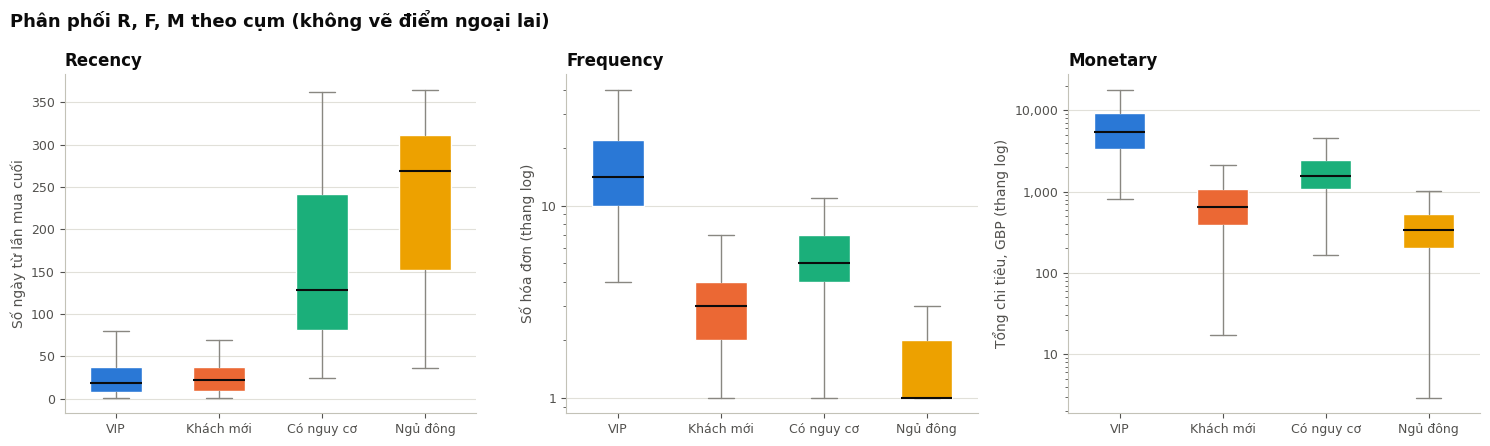

In [15]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4.5))
for ax, col, ylabel in [
    (axes[0], "Recency", "Số ngày từ lần mua cuối"),
    (axes[1], "Frequency", "Số hóa đơn (thang log)"),
    (axes[2], "Monetary", "Tổng chi tiêu, GBP (thang log)"),
]:
    data = [rfm.loc[rfm["ClusterName"] == name, col] for name in CLUSTER_ORDER]
    box = ax.boxplot(data, patch_artist=True, widths=0.5, showfliers=False,
                     medianprops=dict(color=INK, linewidth=1.5),
                     whiskerprops=dict(color=MUTED), capprops=dict(color=MUTED))
    for patch, name in zip(box["boxes"], CLUSTER_ORDER):
        patch.set_facecolor(CLUSTER_COLORS[name])
        patch.set_edgecolor("white")
    ax.set_xticks(range(1, K + 1), CLUSTER_ORDER)
    ax.set_title(col)
    ax.set_ylabel(ylabel)
    if col != "Recency":
        ax.set_yscale("log")
        ax.yaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f"{x:,.0f}"))
fig.suptitle("Phân phối R, F, M theo cụm (không vẽ điểm ngoại lai)", x=0.01, ha="left",
             fontsize=13, fontweight="bold")
fig.tight_layout()
save_fig(fig, "02_boxplot_rfm_theo_cum.png")
plt.show()

### 8.3. Biểu đồ phân tán 2 chiều bằng PCA

PCA chiếu 3 chiều (R, F, M đã chuẩn hóa) xuống 2 thành phần chính để vẽ. Để dễ nhìn, mỗi ô làm nổi bật một cụm, các cụm khác tô xám.

Tỷ lệ phương sai giải thích: PC1 = 73.6%, PC2 = 21.6%, tổng = 95.2%
Hệ số (loadings) của các thành phần chính:


,Recency,Frequency,Monetary
PC1,-0.48,0.63,0.61
PC2,0.88,0.28,0.40


Đã lưu: figures/02_pca_scatter.png


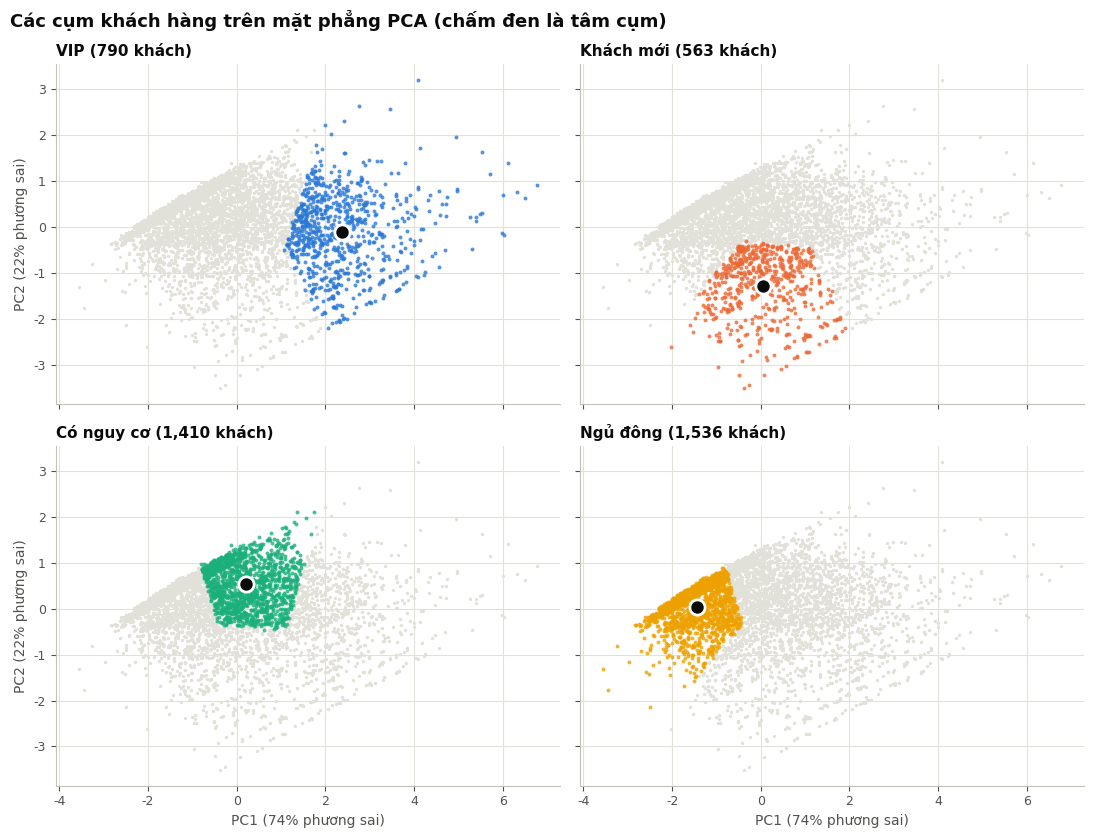

In [16]:
pca = PCA(n_components=2, random_state=RANDOM_STATE)
X_pca = pca.fit_transform(X)
explained = pca.explained_variance_ratio_
print(f"Tỷ lệ phương sai giải thích: PC1 = {explained[0]:.1%}, PC2 = {explained[1]:.1%}, "
      f"tổng = {explained.sum():.1%}")
print("Hệ số (loadings) của các thành phần chính:")
display(pd.DataFrame(pca.components_, columns=RFM_COLS, index=["PC1", "PC2"]).round(3))

fig, axes = plt.subplots(2, 2, figsize=(11, 8.5), sharex=True, sharey=True)
for ax, name in zip(axes.ravel(), CLUSTER_ORDER):
    mask = (rfm["ClusterName"] == name).to_numpy()
    ax.scatter(X_pca[~mask, 0], X_pca[~mask, 1], s=6, color=GRID, linewidths=0)
    ax.scatter(X_pca[mask, 0], X_pca[mask, 1], s=8, color=CLUSTER_COLORS[name], linewidths=0, alpha=0.8)
    center = X_pca[mask].mean(axis=0)
    ax.scatter(*center, s=120, color=INK, edgecolor="white", linewidth=2, zorder=3)
    ax.set_title(f"{name} ({mask.sum():,} khách)", fontsize=11)
    ax.grid(axis="x", visible=True)
for ax in axes[1]:
    ax.set_xlabel(f"PC1 ({explained[0]:.0%} phương sai)")
for ax in axes[:, 0]:
    ax.set_ylabel(f"PC2 ({explained[1]:.0%} phương sai)")
fig.suptitle("Các cụm khách hàng trên mặt phẳng PCA (chấm đen là tâm cụm)", x=0.01, ha="left",
             fontsize=13, fontweight="bold")
fig.tight_layout()
save_fig(fig, "02_pca_scatter.png")
plt.show()

**Nhận xét:** - Hai thành phần chính giữ được **95% phương sai** nên hình chiếu 2 chiều phản ánh khá đầy đủ dữ liệu 3 chiều.
- **PC1** (74%) có hệ số dương lớn với Frequency, Monetary và âm với Recency, có thể hiểu là trục **"giá trị khách hàng"**. **PC2** (22%) chủ yếu là Recency, tức trục **"đã lâu chưa mua"**.
- VIP nằm bên phải (giá trị cao), Ngủ đông nằm bên trái (giá trị thấp); Khách mới nằm phía dưới (Recency thấp), Có nguy cơ nằm ở giữa và lệch lên trên.
- Các cụm nằm sát nhau, không có khoảng trống rõ rệt giữa chúng, khớp với Silhouette 0,36: K-Means đang chia một "đám mây" khách hàng liên tục thành những vùng có ý nghĩa kinh doanh, chứ không phải tìm ra các nhóm tách biệt tự nhiên.

### 8.4. Tỷ trọng khách hàng, doanh thu và tỷ lệ churn theo cụm

Đã lưu: figures/02_ty_trong_va_churn_theo_cum.png


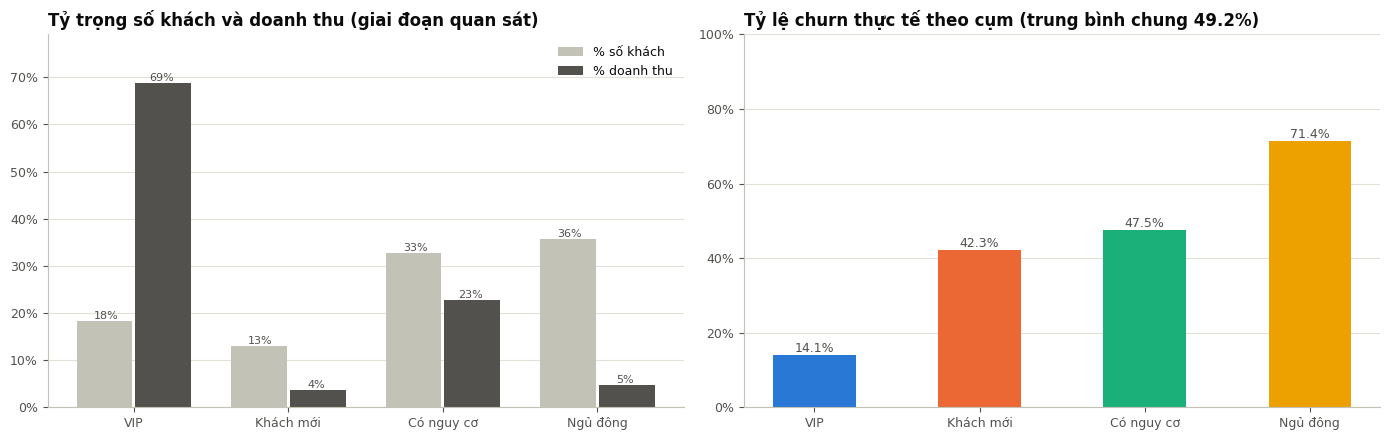

In [17]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))

# Left: share of customers vs share of revenue
x = np.arange(K)
w = 0.36
ax = axes[0]
ax.bar(x - w / 2 - 0.01, cluster_profile["CustomerShare"], width=w, color="#c3c2b7", label="% số khách")
ax.bar(x + w / 2 + 0.01, cluster_profile["RevenueShare"], width=w, color=INK_2, label="% doanh thu")
for i in range(K):
    ax.text(x[i] - w / 2, cluster_profile["CustomerShare"].iloc[i], f"{cluster_profile['CustomerShare'].iloc[i]:.0f}%",
            ha="center", va="bottom", fontsize=8, color=INK_2)
    ax.text(x[i] + w / 2, cluster_profile["RevenueShare"].iloc[i], f"{cluster_profile['RevenueShare'].iloc[i]:.0f}%",
            ha="center", va="bottom", fontsize=8, color=INK_2)
ax.set_xticks(x, CLUSTER_ORDER)
ax.yaxis.set_major_formatter(mticker.PercentFormatter())
ax.set_ylim(0, cluster_profile[["CustomerShare", "RevenueShare"]].max().max() * 1.15)
ax.set_title("Tỷ trọng số khách và doanh thu (giai đoạn quan sát)")
ax.legend(loc="upper right")

# Right: churn rate per cluster
ax = axes[1]
overall_churn = rfm["churn"].mean() * 100
ax.bar(x, cluster_profile["ChurnRate"], width=0.5, color=[CLUSTER_COLORS[n] for n in CLUSTER_ORDER])
for i, v in enumerate(cluster_profile["ChurnRate"]):
    ax.text(i, v, f"{v:.1f}%", ha="center", va="bottom", fontsize=9, color=INK_2)
ax.set_xticks(x, CLUSTER_ORDER)
ax.yaxis.set_major_formatter(mticker.PercentFormatter())
ax.set_ylim(0, 100)
ax.set_title(f"Tỷ lệ churn thực tế theo cụm (trung bình chung {overall_churn:.1f}%)")
fig.tight_layout()
save_fig(fig, "02_ty_trong_va_churn_theo_cum.png")
plt.show()

**Nhận xét:** - **Doanh thu tập trung rất mạnh**: VIP chỉ chiếm 18% số khách nhưng mang lại 69% doanh thu. Một khách VIP trung bình chi tiêu gấp khoảng 28 lần một khách Ngủ đông (£11.089 so với £396). Giữ chân VIP vì thế là ưu tiên số một về giá trị.
- **Tỷ lệ churn tăng dần** theo thứ tự VIP (14%) -> Khách mới (42%) -> Có nguy cơ (48%) -> Ngủ đông (71%). Dù thuật toán phân cụm không hề dùng nhãn churn, các cụm RFM đã chứa nhiều thông tin về nguy cơ rời bỏ. Đây là cơ sở để đưa nhãn cụm làm đặc trưng cho mô hình dự đoán ở notebook 03.
- Tuy vậy, ngay cả VIP vẫn có 14% rời bỏ, còn 29% khách Ngủ đông vẫn quay lại mua. Cụm chỉ cho biết nguy cơ **trung bình của nhóm**; để biết khách cụ thể nào sắp rời bỏ, cần mô hình dự đoán ở mức từng khách hàng.

## 9. Xuất dữ liệu

File được ghi với mã hóa `utf-8-sig` để tên cụm tiếng Việt hiển thị đúng khi mở bằng Excel.

In [18]:
customers_clustered = rfm.reset_index()[["CustomerID", "Recency", "Frequency", "Monetary", "Cluster", "ClusterName", "churn"]]
customers_clustered.to_csv(PROCESSED_DIR / "customers_clustered.csv", index=False, encoding="utf-8-sig")
print(customers_clustered.shape)
customers_clustered.head()

(4299, 7)


,CustomerID,Recency,Frequency,Monetary,Cluster,ClusterName,churn
0,12347,39,6,"3,402.39",2,Có nguy cơ,0
1,12348,158,4,"1,388.40",2,Có nguy cơ,0
2,12349,317,2,"2,221.14",2,Có nguy cơ,0
3,12350,220,1,294.40,3,Ngủ đông,1
4,12351,285,1,300.93,3,Ngủ đông,1


## 10. Tóm tắt

| Nội dung | Kết quả |
|---|---|
| Dữ liệu | 4.299 khách, giao dịch trước 10/09/2011 |
| Tiền xử lý | `log1p` cho R, F, M rồi `StandardScaler` |
| Số cụm | k = 4 (đỉnh Silhouette cục bộ 0,361; Davies-Bouldin 0,907) |
| Thuật toán | K-Means tốt hơn Agglomerative (Ward) và GMM trên cả Silhouette và Davies-Bouldin |
| Các cụm | VIP (18% khách, 69% doanh thu, churn 14%), Khách mới (13%, 4%, 42%), Có nguy cơ (33%, 23%, 48%), Ngủ đông (36%, 5%, 71%) |

Nhãn cụm (`Cluster`, `ClusterName`) được lưu trong `customers_clustered.csv` để dùng làm đặc trưng ở notebook 03 và để tìm luật kết hợp theo cụm ở notebook 04.